# ML5: Implement K-Nearest Neighbors algorithm on diabetes.csv dataset.
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Compute confusion matrix, accuracy, error rate, precision and recall on  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;the given dataset.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Dataset: https://www.kaggle.com/datasets/abdallamahgoub/diabetes  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(download "diabetes.csv" and keep it in the same folder as this file)  

## Theory

### 1. DATASET (Pima Indians Diabetes)
&nbsp;&nbsp;&nbsp;768 records, 8 features: Pregnancies, Glucose, BloodPressure,  
&nbsp;&nbsp;&nbsp;SkinThickness, Insulin, BMI, Pedigree (DiabetesPedigreeFunction), Age;  
&nbsp;&nbsp;&nbsp;target Outcome (1 = diabetic, 0 = non-diabetic).  
&nbsp;&nbsp;&nbsp;Several columns contain 0 where 0 is physically impossible (Glucose,  
&nbsp;&nbsp;&nbsp;BloodPressure, SkinThickness, Insulin, BMI) -&gt; treated as MISSING VALUES and  
&nbsp;&nbsp;&nbsp;replaced by the column MEDIAN (imputation, Unit II).  

### 2. K-NEAREST NEIGHBOURS ALGORITHM
&nbsp;&nbsp;&nbsp;Non-parametric, lazy (instance-based) supervised learner.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;1. Choose k.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;2. For a test point compute distance to every training point  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(Euclidean d = sqrt(SUM (x\_i - y\_i)^2)).  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3. Select the k closest points.  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4. Assign the class that is in MAJORITY among them  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(regression: average of their values).  
&nbsp;&nbsp;&nbsp;Properties: no training phase; prediction O(n.d); sensitive to scale  
&nbsp;&nbsp;&nbsp;(so features are STANDARDIZED) and to irrelevant features; "curse of  
&nbsp;&nbsp;&nbsp;dimensionality". k chosen by validation, commonly sqrt(n), odd for binary.  
&nbsp;&nbsp;&nbsp;Small k -&gt; overfitting (high variance), large k -&gt; underfitting (high bias).  
&nbsp;&nbsp;&nbsp;Weighted KNN gives closer neighbours more weight (1/d).  

### 3. CONFUSION MATRIX &amp; METRICS
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Predicted 0   Predicted 1  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Actual 0            TN            FP  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Actual 1            FN            TP  
&nbsp;&nbsp;&nbsp;Accuracy   = (TP + TN) / (TP + TN + FP + FN)  
&nbsp;&nbsp;&nbsp;Error rate = (FP + FN) / total = 1 - Accuracy  
&nbsp;&nbsp;&nbsp;Precision  = TP / (TP + FP)   -&gt; exactness of positive predictions  
&nbsp;&nbsp;&nbsp;Recall     = TP / (TP + FN)   -&gt; sensitivity / true positive rate  
&nbsp;&nbsp;&nbsp;F1         = 2 PR / (P + R)  
&nbsp;&nbsp;&nbsp;Specificity = TN / (TN + FP)  
&nbsp;&nbsp;&nbsp;In medical diagnosis RECALL is critical: a False Negative means a diabetic  
&nbsp;&nbsp;&nbsp;patient is missed.  

### Conclusion
KNN with scaled features and median-imputed zeros gives about
70-78% accuracy on the diabetes dataset; metrics are computed manually from the  
confusion matrix and verified with scikit-learn.

In [1]:
%matplotlib inline

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score,
                             classification_report)

DATA = "diabetes.csv"   # CSV file kept next to this notebook

### 1. Read & pre-process

In [3]:
df = pd.read_csv(DATA)
print("Shape:", df.shape)
print(df.head())
print(df.describe().T)

target = "Outcome"
zero_invalid = [c for c in ["Glucose", "BloodPressure", "SkinThickness",
                            "Insulin", "BMI"] if c in df.columns]
print("\nZero counts (invalid values):\n", (df[zero_invalid] == 0).sum())
for c in zero_invalid:
    df[c] = df[c].replace(0, np.nan)
    df[c] = df[c].fillna(df[c].median())

X = df.drop(columns=[target])
y = df[target]
print("\nClass distribution:\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
               count        mean         std     min       25%       50%  \
Pregnancies    768.0    3.845052    3.369578   0.000   1.00000    3.0000   
Glucose        768.0  120.894531   31.972618   0.000  99.00000  117.0000   
BloodPressure  768.0   69.105469   19.355807   0.000  62.00000   72.0000   
SkinThickness  768.0   20.536458   15.952218   0.000   0.00000   23.0000   
Ins

### 2. Choose k


Best k (lowest error) = 21


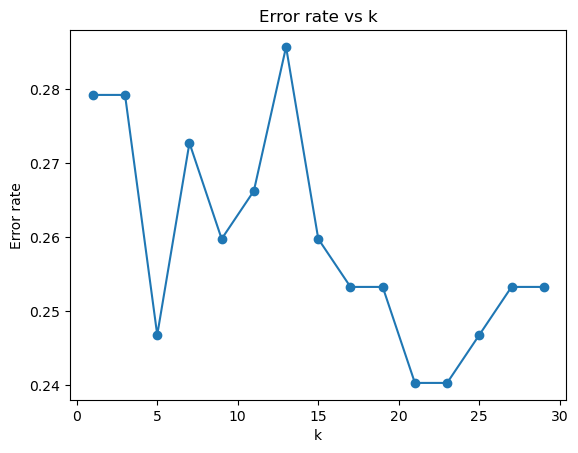

In [4]:
errors = []
ks = range(1, 31, 2)                    # odd k avoids ties in voting
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    errors.append(1 - accuracy_score(y_test, m.predict(X_test)))
best_k = list(ks)[int(np.argmin(errors))]
print("\nBest k (lowest error) =", best_k)

plt.plot(list(ks), errors, marker="o")
plt.xlabel("k")
plt.ylabel("Error rate")
plt.title("Error rate vs k")
plt.show()

### 3. Final KNN model

In [5]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

### 4. Metrics


Confusion matrix:
 [[87 13]
 [24 30]]
TN = 87, FP = 13, FN = 24, TP = 30
Accuracy   = (TP+TN)/total = 0.7597
Error rate = (FP+FN)/total = 0.2403
Precision  = TP/(TP+FP)    = 0.6977
Recall     = TP/(TP+FN)    = 0.5556

Verification with sklearn:
Accuracy  0.7597
Precision 0.6977
Recall    0.5556
              precision    recall  f1-score   support

Non-diabetic       0.78      0.87      0.82       100
    Diabetic       0.70      0.56      0.62        54

    accuracy                           0.76       154
   macro avg       0.74      0.71      0.72       154
weighted avg       0.75      0.76      0.75       154



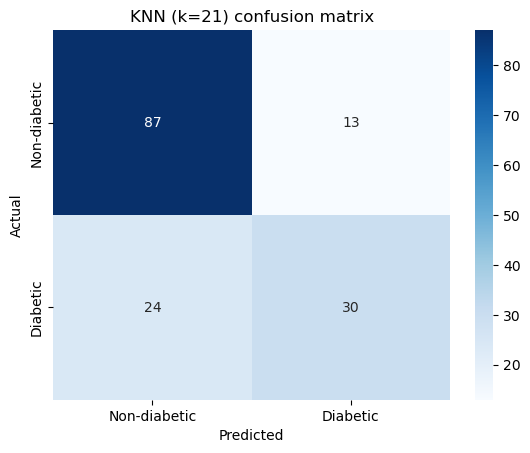

In [6]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
total = tn + fp + fn + tp

print("\nConfusion matrix:\n", cm)
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Accuracy   = (TP+TN)/total = {(tp + tn) / total:.4f}")
print(f"Error rate = (FP+FN)/total = {(fp + fn) / total:.4f}")
print(f"Precision  = TP/(TP+FP)    = {tp / (tp + fp):.4f}")
print(f"Recall     = TP/(TP+FN)    = {tp / (tp + fn):.4f}")

print("\nVerification with sklearn:")
print(f"Accuracy  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision {precision_score(y_test, y_pred):.4f}")
print(f"Recall    {recall_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred,
                            target_names=["Non-diabetic", "Diabetic"]))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-diabetic", "Diabetic"],
            yticklabels=["Non-diabetic", "Diabetic"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"KNN (k={best_k}) confusion matrix")
plt.show()